# Clustering Gempa Bumi Global Menggunakan K-Means
**Praktikum Analisis Big Data — Clustering (K-Means) | Dataset: `global_earthquakes_seismic.csv`**

Notebook ini mengelompokkan ±10.000 kejadian gempa bumi global (Juli 2025 – Oktober 2026) berdasarkan karakteristik seismiknya menggunakan **K-Means**, mengikuti 7 langkah praktikum:

1. Pemahaman dan pengambilan dataset
2. Eksplorasi data (EDA)
3. Pra-pemrosesan data
4. Penerapan algoritma K-Means (Elbow & Silhouette)
5. Evaluasi dan analisis hasil
6. Visualisasi hasil
7. Dashboard Streamlit (`app.py`)

Seluruh keluaran (dataset siap clustering, hasil clustering, dan metadata) disimpan di folder `artifacts/` dan dibaca oleh `app.py`.

In [1]:
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401  (diperlukan untuk plot 3D)

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.feature_selection import f_classif
from sklearn.metrics import silhouette_score, silhouette_samples, davies_bouldin_score

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

SEED = 42          # agar hasil clustering dapat direproduksi
N_INIT = 20        # jumlah inisialisasi centroid K-Means
ARTIFACTS_DIR = Path("artifacts")
ARTIFACTS_DIR.mkdir(exist_ok=True)
print("Library siap digunakan. Folder keluaran:", ARTIFACTS_DIR.resolve())

Library siap digunakan. Folder keluaran: C:\test3 Clustering K-Means\artifacts


---
## Langkah 1 — Pemahaman dan Pengambilan Dataset
1. **Dataset numerik open source**: catatan kejadian gempa bumi global (magnitudo ≥ 4,5) berformat `.csv`, bersumber dari katalog USGS.
2. **Impor ke Python** dengan `pandas`.
3. **Tampilkan struktur data**: jumlah baris, kolom, tipe data, dan ringkasan statistik.
4. **Identifikasi fitur numerik** yang dipakai untuk clustering beserta alasan pemilihannya.

In [2]:
CSV_NAME = "global_earthquakes_seismic.csv"
CANDIDATE_PATHS = [
    Path("C:\test3 Clustering K-Means\global_earthquakes_seismic.csv"),
    Path("C:\test3 Clustering K-Means\global_earthquakes_seismic.csv"),
    Path(CSV_NAME),
    Path("data") / CSV_NAME,
    Path("..") / CSV_NAME,
]
DATA_PATH = next((p for p in CANDIDATE_PATHS if p.exists()), None)
if DATA_PATH is None:                       # cari otomatis di folder kerja
    found = list(Path(".").rglob(CSV_NAME))
    DATA_PATH = found[0] if found else None
if DATA_PATH is None:
    raise FileNotFoundError(f"File {CSV_NAME} tidak ditemukan. Letakkan di samping notebook atau isi CANDIDATE_PATHS.")
print("[INFO] Dataset ditemukan di:", DATA_PATH.resolve())

df_raw = pd.read_csv(DATA_PATH)
df_raw["waktu"] = pd.to_datetime(df_raw["time"], unit="ms")   # kolom 'time' berupa epoch milidetik

print("=" * 65)
print("STRUKTUR DATASET")
print("=" * 65)
print(f"Jumlah Baris   : {df_raw.shape[0]:,}")
print(f"Jumlah Kolom   : {df_raw.shape[1] - 1} (+1 kolom 'waktu' hasil konversi)")
print(f"Rentang Waktu  : {df_raw['waktu'].min():%d %b %Y} s.d. {df_raw['waktu'].max():%d %b %Y}")
display(df_raw.drop(columns=["evidence_span", "cot_rationale"], errors="ignore").head())

[INFO] Dataset ditemukan di: C:\test3 Clustering K-Means\global_earthquakes_seismic.csv
STRUKTUR DATASET
Jumlah Baris   : 10,000
Jumlah Kolom   : 25 (+1 kolom 'waktu' hasil konversi)
Rentang Waktu  : 30 Jul 2025 s.d. 13 Oct 2026


,id,time,latitude,longitude,depth,mag,magType,place,status,tsunami,...,rms,gap,type,title,magnitude_severity_class,focal_depth_regime,tsunami_hazard_potential,tectonic_boundary_zone,confidence_score,waktu
0,us6000u20i,1791884908205,-9.9266,118.8246,35.0,4.5,mb,"71 km SW of Tambolaka, Indonesia",reviewed,0,...,0.67,123.0,earthquake,"M 4.5 - 71 km SW of Tambolaka, Indonesia",moderate,shallow_crustal,inland_negligible,ring_of_fire_pacific,0.98,2026-10-13 09:48:28.205
1,us6000u20g,1791884472899,38.5166,68.8922,10.0,4.7,mb,"9 km NE of Boshkengash, Tajikistan",reviewed,0,...,0.70,62.0,earthquake,"M 4.7 - 9 km NE of Boshkengash, Tajikistan",moderate,shallow_crustal,inland_negligible,alpide_himalayan_belt,0.98,2026-10-13 09:41:12.899
2,us6000u207,1791880708325,-28.5560,-12.5205,10.0,5.3,mb,southern Mid-Atlantic Ridge,reviewed,0,...,1.03,63.0,earthquake,M 5.3 - southern Mid-Atlantic Ridge,moderate,shallow_crustal,inland_negligible,mid_ocean_ridge_divergent,0.98,2026-10-13 08:38:28.325
3,us6000u1zh,1791873544944,7.7685,-81.4531,10.0,4.7,mb,"14 km WNW of Río Grande, Panama",reviewed,0,...,0.80,140.0,earthquake,"M 4.7 - 14 km WNW of Río Grande, Panama",moderate,shallow_crustal,inland_negligible,ring_of_fire_pacific,0.98,2026-10-13 06:39:04.944
4,us6000u1zc,1791871284155,19.6853,120.7047,10.0,4.7,mb,"124 km N of Pagudpud, Philippines",reviewed,0,...,0.95,132.0,earthquake,"M 4.7 - 124 km N of Pagudpud, Philippines",moderate,shallow_crustal,inland_negligible,ring_of_fire_pacific,0.98,2026-10-13 06:01:24.155


In [3]:
# Tipe data tiap kolom
tipe = pd.DataFrame({
    "Tipe Data": df_raw.dtypes.astype(str),
    "Nilai Unik": df_raw.nunique(),
    "Missing Value": df_raw.isna().sum(),
})
display(tipe)

# Ringkasan statistik kolom numerik
display(df_raw.describe().T.round(3))

,Tipe Data,Nilai Unik,Missing Value
id,object,10000,0
time,int64,10000,0
latitude,float64,9902,0
longitude,float64,9923,0
depth,float64,4154,0
mag,float64,54,0
magType,object,8,0
place,object,6821,0
status,object,1,0
tsunami,int64,2,0


,count,mean,min,25%,50%,75%,max,std
time,10000.0,1771917356330.238281,1753890068273.0,1760858167777.75,1772139731421.5,1782527070837.75,1791884908205.0,11690270724.464773
latitude,10000.0,7.828576,-67.4686,-15.4493,5.19465,38.385925,85.0643,31.909441
longitude,10000.0,61.65019,-179.997,-32.6293,125.0271,152.264525,179.9899,116.440894
depth,10000.0,56.165777,0.0,10.0,11.0,56.99325,669.556,101.577053
mag,10000.0,4.812037,4.5,4.5,4.7,5.0,7.8,0.367266
tsunami,10000.0,0.0084,0.0,0.0,0.0,0.0,1.0,0.09127
sig,10000.0,362.5626,312.0,313.0,340.0,385.0,2910.0,87.915594
nst,10000.0,66.7819,0.0,34.0,55.0,85.0,566.0,46.855809
dmin,10000.0,4.128023,0.0,1.498,2.4935,4.651,55.307,5.263083
rms,10000.0,0.762471,0.12,0.61,0.74,0.9,3.9,0.219922


In [4]:
# Identifikasi fitur untuk clustering
FEATURES = ["depth", "mag", "nst", "dmin", "gap"]
LOG_FEATURES = ["depth", "dmin", "nst"]      # fitur sangat miring -> ditransformasi log1p sebelum standarisasi (Langkah 3)

peran_fitur = pd.DataFrame([
    ("depth", "DIPAKAI", "Kedalaman hiposenter (km): pembeda utama jenis gempa dangkal vs dalam."),
    ("mag", "DIPAKAI", "Magnitudo: ukuran kekuatan gempa."),
    ("nst", "DIPAKAI", "Jumlah stasiun seismik yang merekam: indikator seberapa jelas gempa terekam."),
    ("dmin", "DIPAKAI", "Jarak horizontal ke stasiun terdekat (derajat): menggambarkan kerapatan jaringan di sekitar episentrum."),
    ("gap", "DIPAKAI", "Celah azimut stasiun (derajat): kualitas geometri jaringan pemantau."),
    ("sig", "TIDAK", "Skor signifikansi turunan magnitudo (korelasi dengan mag = 0,80) -> redundan, akan menggandakan bobot magnitudo."),
    ("rms", "TIDAK", "Residual waktu tempuh: nyaris tidak berkorelasi dengan fitur lain (|r| < 0,15) sehingga hanya menambah derau."),
    ("latitude / longitude", "TIDAK", "Koordinat geografis: jarak Euclidean pada derajat tidak valid di bola bumi. Dipakai untuk peta, bukan untuk clustering."),
    ("tsunami", "TIDAK", "Variabel biner (0/1) dan sangat jarang (<1%): dipakai untuk profil klaster."),
    ("confidence_score", "TIDAK", "Anotasi kualitas data (hanya 2 nilai), bukan pengukuran fisik."),
], columns=["Fitur", "Status", "Alasan"])
pd.set_option("display.max_colwidth", 200)
display(peran_fitur)
print("\nFitur clustering terpilih :", FEATURES)

,Fitur,Status,Alasan
0,depth,DIPAKAI,Kedalaman hiposenter (km): pembeda utama jenis gempa dangkal vs dalam.
1,mag,DIPAKAI,Magnitudo: ukuran kekuatan gempa.
2,nst,DIPAKAI,Jumlah stasiun seismik yang merekam: indikator seberapa jelas gempa terekam.
3,dmin,DIPAKAI,Jarak horizontal ke stasiun terdekat (derajat): menggambarkan kerapatan jaringan di sekitar episentrum.
4,gap,DIPAKAI,Celah azimut stasiun (derajat): kualitas geometri jaringan pemantau.
5,sig,TIDAK,"Skor signifikansi turunan magnitudo (korelasi dengan mag = 0,80) -> redundan, akan menggandakan bobot magnitudo."
6,rms,TIDAK,"Residual waktu tempuh: nyaris tidak berkorelasi dengan fitur lain (|r| < 0,15) sehingga hanya menambah derau."
7,latitude / longitude,TIDAK,"Koordinat geografis: jarak Euclidean pada derajat tidak valid di bola bumi. Dipakai untuk peta, bukan untuk clustering."
8,tsunami,TIDAK,Variabel biner (0/1) dan sangat jarang (<1%): dipakai untuk profil klaster.
9,confidence_score,TIDAK,"Anotasi kualitas data (hanya 2 nilai), bukan pengukuran fisik."



Fitur clustering terpilih : ['depth', 'mag', 'nst', 'dmin', 'gap']


---
## Langkah 2 — Eksplorasi Data (EDA)
Lihat distribusi tiap fitur, periksa missing value, dan amati hubungan antar fitur.

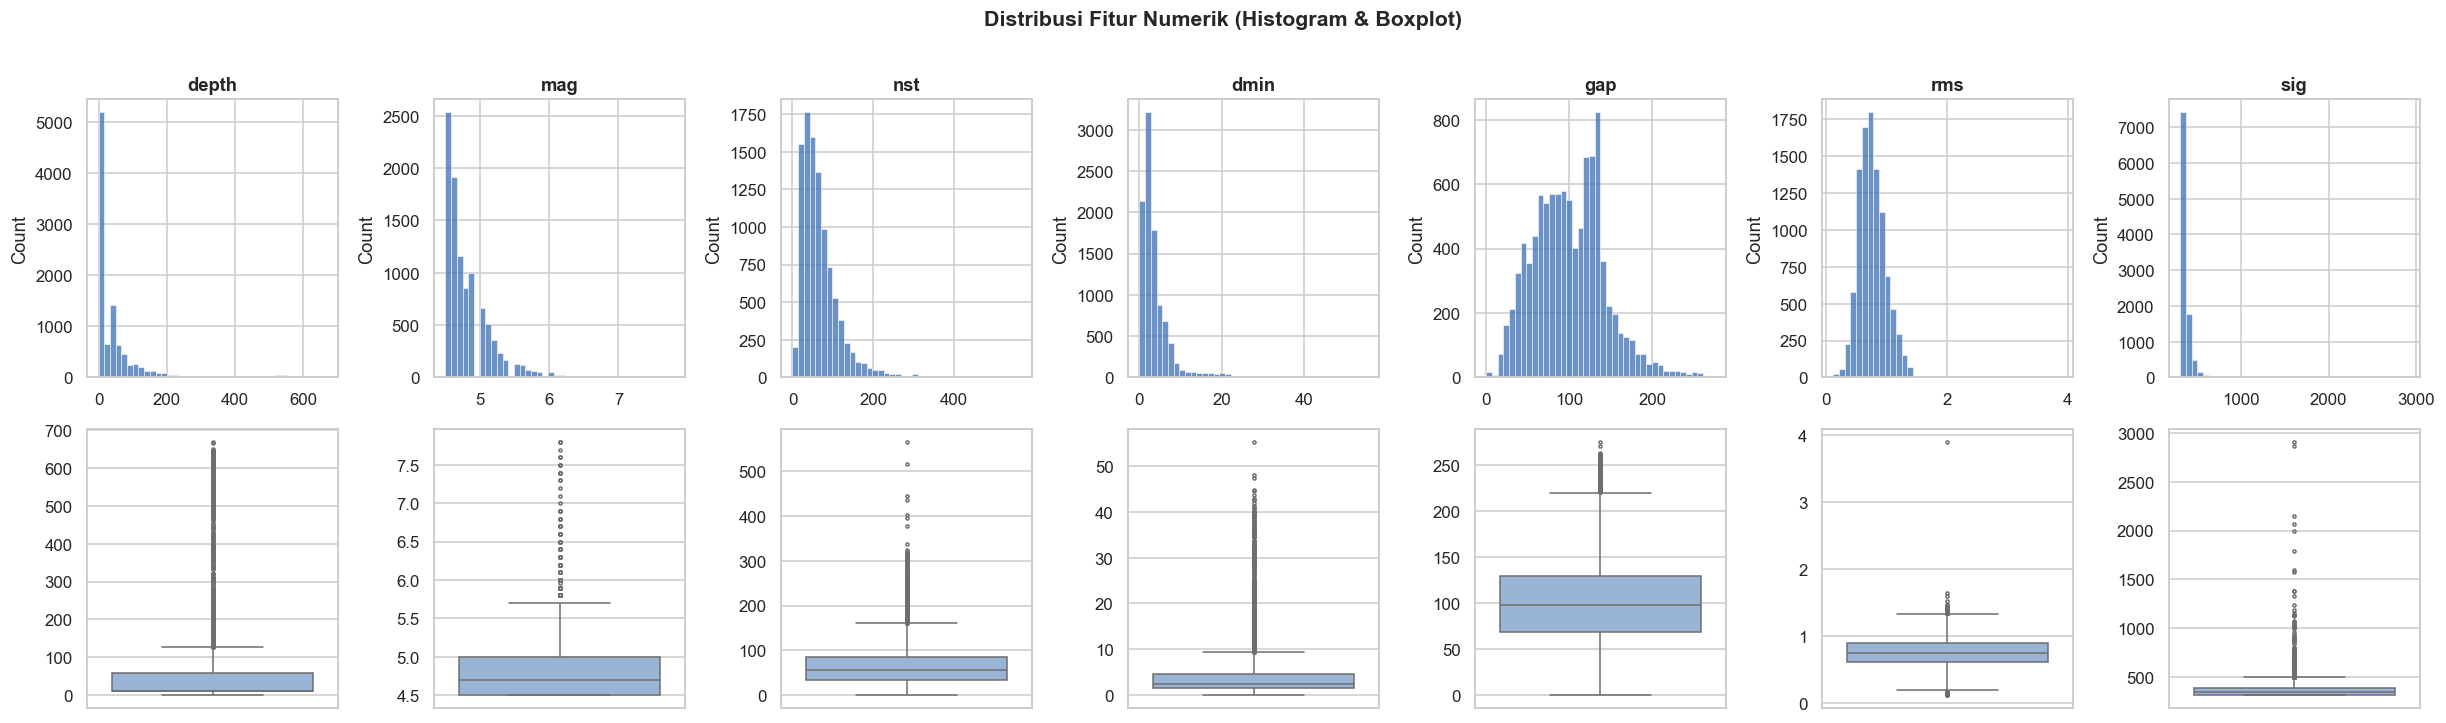

Kemiringan distribusi (skewness):
sig      10.34
dmin      3.78
depth     3.76
mag       2.25
nst       2.07
rms       0.69
gap       0.43

-> depth, dmin, nst, sig sangat miring ke kanan (skew > 1); ini menjadi dasar transformasi log pada Langkah 3.


In [5]:
# 2.1 Distribusi fitur: histogram (atas) dan boxplot (bawah)
EDA_COLS = ["depth", "mag", "nst", "dmin", "gap", "rms", "sig"]
fig, axes = plt.subplots(2, len(EDA_COLS), figsize=(3.2 * len(EDA_COLS), 6.5))
for j, col in enumerate(EDA_COLS):
    sns.histplot(df_raw[col], bins=40, ax=axes[0, j], color="#3B6FB6")
    axes[0, j].set_title(col, fontweight="bold"); axes[0, j].set_xlabel("")
    sns.boxplot(y=df_raw[col], ax=axes[1, j], color="#8FB3E0", fliersize=2)
    axes[1, j].set_ylabel("")
plt.suptitle("Distribusi Fitur Numerik (Histogram & Boxplot)", fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout(); plt.show()

skew = df_raw[EDA_COLS].skew().round(2).sort_values(ascending=False)
print("Kemiringan distribusi (skewness):")
print(skew.to_string())
print("\n-> depth, dmin, nst, sig sangat miring ke kanan (skew > 1); ini menjadi dasar transformasi log pada Langkah 3.")

In [6]:
# 2.2 Missing value, nilai tak terukur, tipe kejadian, dan duplikasi
print("Missing value (NaN) per kolom   :", int(df_raw.isna().sum().sum()), "-> tidak ada NaN")

zero_cols = ["nst", "gap", "dmin"]
print("\nNilai 0 pada kolom pengukuran jaringan (kemungkinan 'tidak terukur'):")
print((df_raw[zero_cols] == 0).sum().to_string())
mask_hidden = (df_raw[zero_cols] == 0).all(axis=1)
print(f"Baris dengan nst = gap = dmin = 0 sekaligus: {int(mask_hidden.sum())} -> tidak mungkin pengukuran asli (missing value tersembunyi)")

print("\nTipe kejadian:"); print(df_raw["type"].value_counts().to_string())
print("\nDuplikasi ID    :", int(df_raw["id"].duplicated().sum()))
print("Duplikasi baris :", int(df_raw.drop(columns=["waktu"]).duplicated().sum()))

Missing value (NaN) per kolom   : 0 -> tidak ada NaN

Nilai 0 pada kolom pengukuran jaringan (kemungkinan 'tidak terukur'):
nst     16
gap     16
dmin    16
Baris dengan nst = gap = dmin = 0 sekaligus: 16 -> tidak mungkin pengukuran asli (missing value tersembunyi)

Tipe kejadian:
type
earthquake    9998
landslide        2

Duplikasi ID    : 0
Duplikasi baris : 0


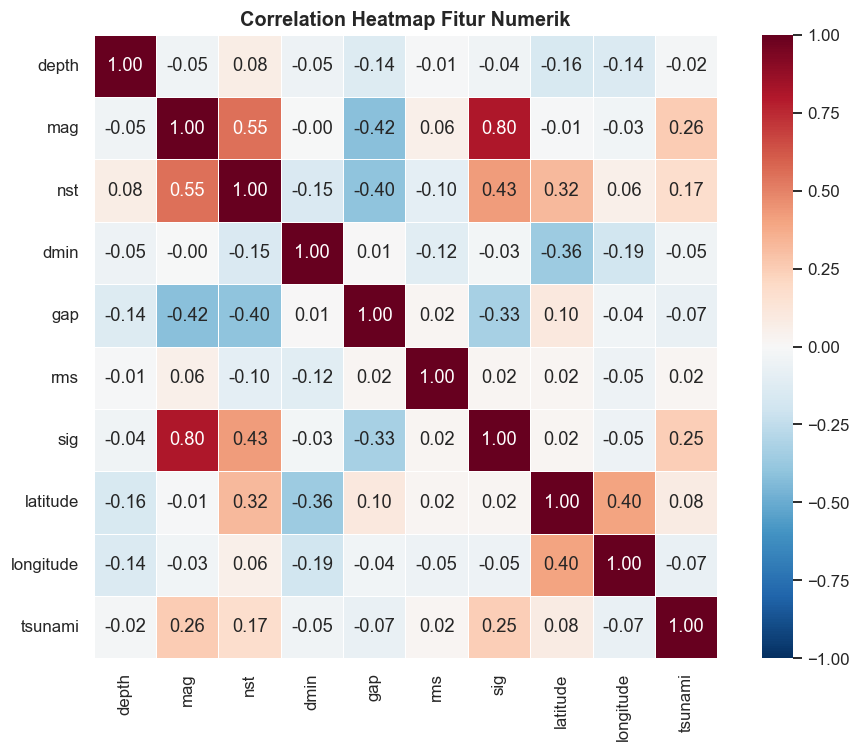

Pasangan fitur dengan korelasi terkuat:


,Fitur A,Fitur B,r,|r|
0,mag,sig,0.80,0.80
1,mag,nst,0.55,0.55
2,nst,sig,0.43,0.43
3,mag,gap,-0.42,0.42
4,nst,gap,-0.40,0.40
5,latitude,longitude,0.40,0.40


In [7]:
# 2.3 Hubungan antar fitur: correlation heatmap
CORR_COLS = ["depth", "mag", "nst", "dmin", "gap", "rms", "sig", "latitude", "longitude", "tsunami"]
corr = df_raw[CORR_COLS].corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, linewidths=.5, square=True)
plt.title("Correlation Heatmap Fitur Numerik", fontsize=13, fontweight="bold")
plt.tight_layout(); plt.show()

pairs = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack().reset_index()
pairs.columns = ["Fitur A", "Fitur B", "r"]
pairs["|r|"] = pairs["r"].abs()
print("Pasangan fitur dengan korelasi terkuat:")
display(pairs.sort_values("|r|", ascending=False).head(6).round(2).reset_index(drop=True))

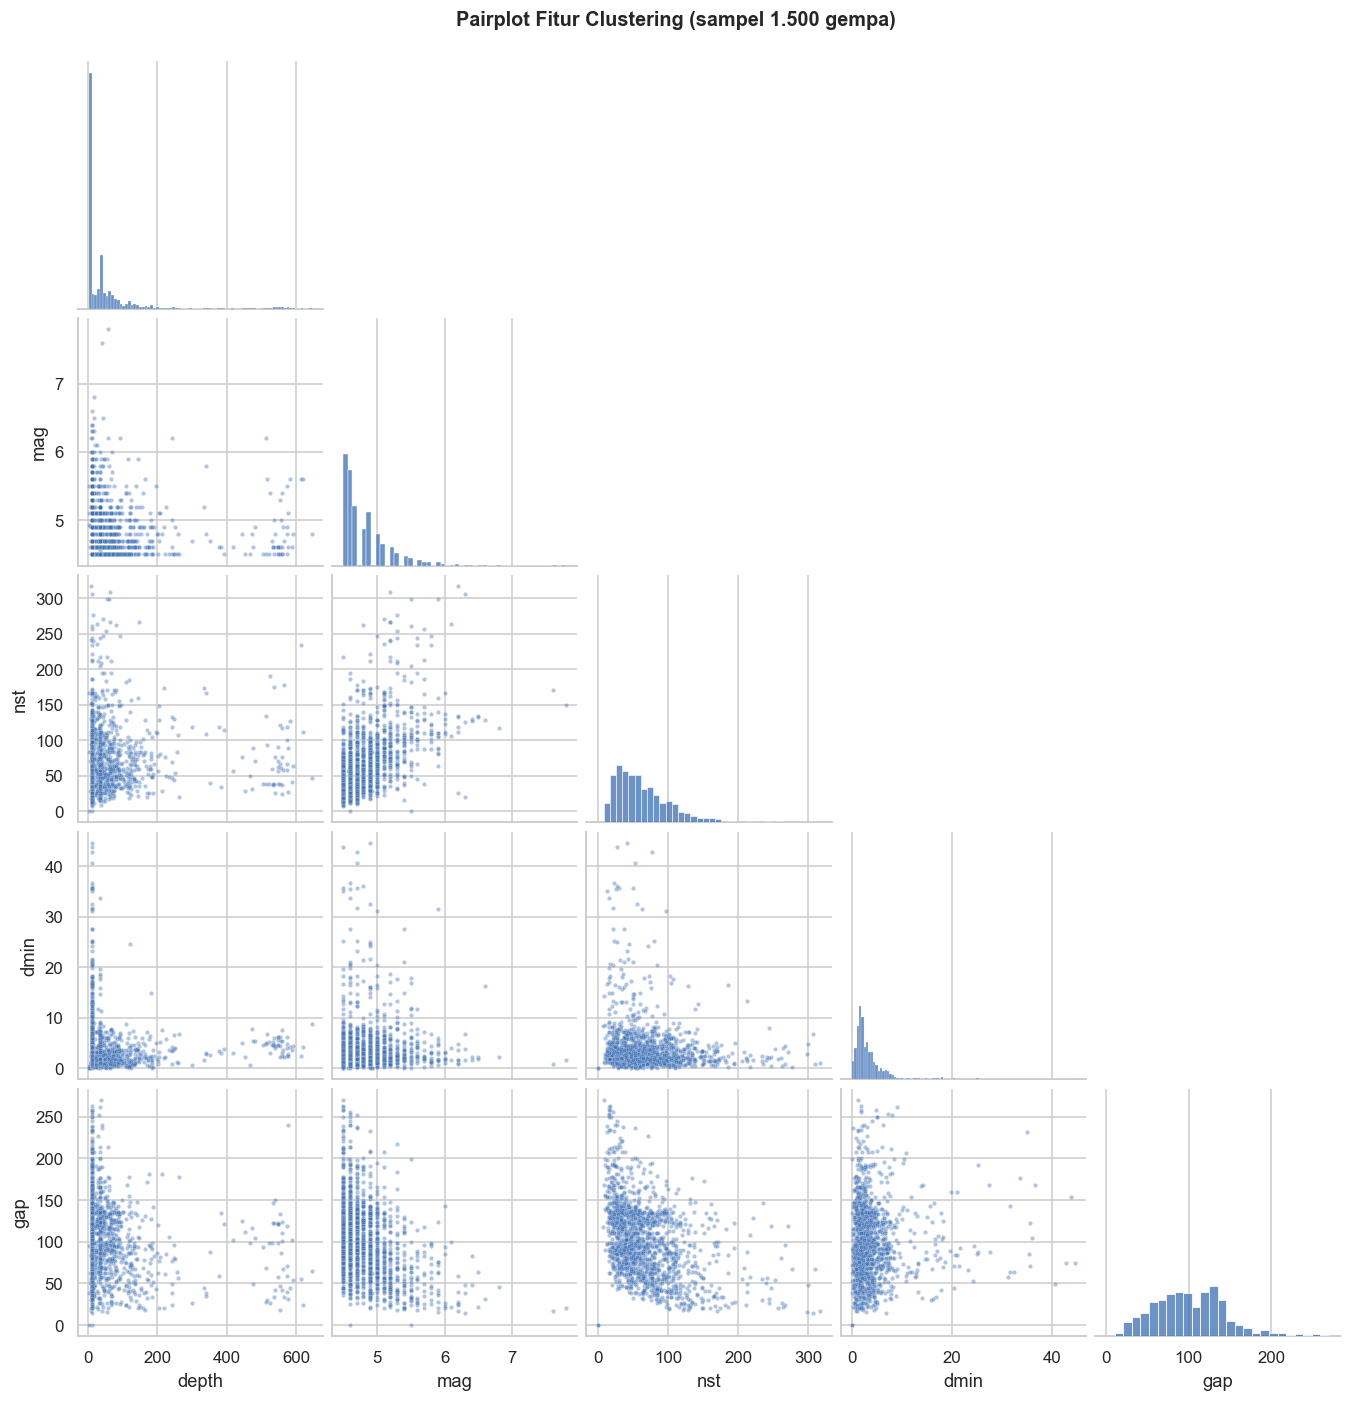

In [8]:
# 2.4 Pairplot fitur clustering (sampel 1.500 titik agar cepat)
sample = df_raw[FEATURES].sample(1500, random_state=SEED)
g = sns.pairplot(sample, corner=True, plot_kws=dict(s=8, alpha=0.4, color="#3B6FB6"), diag_kws=dict(color="#3B6FB6"))
g.fig.suptitle("Pairplot Fitur Clustering (sampel 1.500 gempa)", fontsize=13, fontweight="bold", y=1.02)
plt.show()

**Catatan EDA**
- Tidak ada `NaN`, tetapi **16 baris memiliki `nst = gap = dmin = 0` sekaligus** (nilai tak terukur; 2 di antaranya juga bukan gempa) dan **2 baris bukan gempa** (`type = landslide`) → dibersihkan di Langkah 3.
- `depth`, `dmin`, dan `nst` sangat miring ke kanan; mayoritas gempa dangkal (median ±11 km) dengan ekor panjang hingga ±670 km.
- `mag` berkorelasi kuat dengan `sig` (r ≈ 0,80) dan `nst` (r ≈ 0,55); gempa besar direkam lebih banyak stasiun dengan `gap` lebih sempit (r ≈ −0,42).
- Fitur yang paling berpengaruh dalam pembentukan klaster ditentukan secara kuantitatif pada Langkah 5 (uji ANOVA F).

---
## Langkah 3 — Pra-Pemrosesan Data
1. Hapus data tidak valid, duplikasi, dan tinjau nilai ekstrem (outlier).
2. Ubah data kategorikal menjadi numerik (encoding).
3. Normalisasi/standarisasi fitur numerik.
4. Simpan hasilnya sebagai dataset siap clustering.

In [9]:
# 3.1 Pembersihan data
df = df_raw.copy()
cleaning_log = []

def hapus(data, mask, alasan):
    n = int(mask.sum())
    cleaning_log.append((alasan, n))
    print(f"- {alasan:<55}: {n} baris dihapus")
    return data.loc[~mask].copy()

df = hapus(df, df["type"] != "earthquake", "Bukan gempa tektonik (type = landslide)")
df = hapus(df, (df[zero_cols] == 0).all(axis=1), "Nilai tak terukur (nst = gap = dmin = 0)")
df = hapus(df, df.duplicated(subset="id"), "ID duplikat")
df = hapus(df, df.duplicated(subset=["time", "latitude", "longitude", "depth", "mag"]), "Baris duplikat (waktu, lokasi, kedalaman, magnitudo)")
df = df.reset_index(drop=True)
print(f"\nData bersih: {len(df):,} dari {len(df_raw):,} baris ({len(df) / len(df_raw):.2%} dipertahankan)")

- Bukan gempa tektonik (type = landslide)                : 2 baris dihapus
- Nilai tak terukur (nst = gap = dmin = 0)               : 14 baris dihapus
- ID duplikat                                            : 0 baris dihapus
- Baris duplikat (waktu, lokasi, kedalaman, magnitudo)   : 0 baris dihapus

Data bersih: 9,984 dari 10,000 baris (99.84% dipertahankan)


In [11]:
# 3.2 Tinjauan outlier (metode IQR 1,5x) pada fitur clustering
rows = []
for c in FEATURES:
    q1, q3 = df[c].quantile([0.25, 0.75]); iqr = q3 - q1
    n_out = int(((df[c] < q1 - 1.5 * iqr) | (df[c] > q3 + 1.5 * iqr)).sum())
    rows.append((c, n_out, round(100 * n_out / len(df), 1), round(df[c].min(), 2), round(df[c].max(), 2)))
display(pd.DataFrame(rows, columns=["Fitur", "Jumlah Outlier (IQR)", "% Data", "Min", "Max"]))
print("Keputusan: outlier TIDAK dihapus. Gempa sangat dalam (hingga ±670 km) dan gempa besar (M ≥ 6) adalah peristiwa")
print("seismik nyata dan justru merupakan kelompok yang ingin ditemukan. Pengaruh ekornya diredam dengan transformasi log1p.")

,Fitur,Jumlah Outlier (IQR),% Data,Min,Max
0,depth,992,9.9,1.18,669.56
1,mag,280,2.8,4.50,7.80
2,nst,447,4.5,8.00,566.00
3,dmin,741,7.4,0.03,55.31
4,gap,100,1.0,9.00,275.00


Keputusan: outlier TIDAK dihapus. Gempa sangat dalam (hingga ±670 km) dan gempa besar (M ≥ 6) adalah peristiwa
seismik nyata dan justru merupakan kelompok yang ingin ditemukan. Pengaruh ekornya diredam dengan transformasi log1p.


In [12]:
# 3.3 Encoding data kategorikal -> numerik
# Kategori berurutan (ordinal) -> ordinal encoding
ORDINAL_MAPS = {
    "magnitude_severity_class": {"moderate": 0, "strong": 1, "major": 2, "great_catastrophic": 3},
    "focal_depth_regime": {"shallow_crustal": 0, "intermediate_subduction": 1, "deep_mantle_slab": 2},
    "tsunami_hazard_potential": {"inland_negligible": 0, "moderate_coastal_alert": 1, "critical_tsunamigenic": 2},
}
ENC_NAMES = {"magnitude_severity_class": "severity_enc", "focal_depth_regime": "depth_regime_enc", "tsunami_hazard_potential": "tsunami_hazard_enc"}
for col, mapping in ORDINAL_MAPS.items():
    df[ENC_NAMES[col]] = df[col].map(mapping)

# Kategori tidak berurutan -> one-hot encoding
df = pd.concat([
    df,
    pd.get_dummies(df["tectonic_boundary_zone"], prefix="zone", dtype=int),
    pd.get_dummies(df["magType"], prefix="magType", dtype=int),
], axis=1)

print("Kolom hasil encoding:", [c for c in df.columns if c.endswith("_enc") or c.startswith(("zone_", "magType_"))])
print("\nCatatan: kolom kategorikal (zona tektonik, rezim kedalaman, dll.) TIDAK dipakai sebagai fitur K-Means karena sebagian")
print("diturunkan langsung dari depth/mag. Kolom tersebut dipakai sebagai pembanding untuk menafsirkan klaster (Langkah 5).")

Kolom hasil encoding: ['severity_enc', 'depth_regime_enc', 'tsunami_hazard_enc', 'zone_alpide_himalayan_belt', 'zone_intraplate_stable', 'zone_mid_ocean_ridge_divergent', 'zone_ring_of_fire_pacific', 'magType_mb', 'magType_md', 'magType_ml', 'magType_mw', 'magType_mwb', 'magType_mwr', 'magType_mww']

Catatan: kolom kategorikal (zona tektonik, rezim kedalaman, dll.) TIDAK dipakai sebagai fitur K-Means karena sebagian
diturunkan langsung dari depth/mag. Kolom tersebut dipakai sebagai pembanding untuk menafsirkan klaster (Langkah 5).


In [13]:
# 3.4 Transformasi log1p (fitur sangat miring) + standarisasi (Z-score)
X = df[FEATURES].copy()
skew_sebelum = X.skew()
for c in LOG_FEATURES:
    X[c] = np.log1p(X[c])
skew_sesudah = X.skew()
display(pd.DataFrame({"Skewness Sebelum": skew_sebelum, "Skewness Sesudah Log": skew_sesudah,
                      "Di-log?": [c in LOG_FEATURES for c in FEATURES]}).round(2))

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
for j, c in enumerate(FEATURES):
    df["z_" + c] = X_scaled[:, j]
print("Rata-rata fitur terstandarisasi :", np.round(X_scaled.mean(axis=0), 3))
print("Std fitur terstandarisasi       :", np.round(X_scaled.std(axis=0), 3))

,Skewness Sebelum,Skewness Sesudah Log,Di-log?
depth,3.76,0.96,True
mag,2.26,2.26,False
nst,2.08,0.01,True
dmin,3.78,0.93,True
gap,0.45,0.45,False


Rata-rata fitur terstandarisasi : [-0.  0.  0.  0. -0.]
Std fitur terstandarisasi       : [1. 1. 1. 1. 1.]


In [14]:
# 3.5 Simpan dataset siap clustering
KOLOM_SIMPAN = (["id", "waktu", "place", "latitude", "longitude", "depth", "mag", "magType", "sig", "nst", "dmin", "rms", "gap",
                 "tsunami", "confidence_score", "magnitude_severity_class", "focal_depth_regime", "tsunami_hazard_potential",
                 "tectonic_boundary_zone"] + list(ENC_NAMES.values())
                + [c for c in df.columns if c.startswith(("zone_", "magType_"))] + ["z_" + c for c in FEATURES])
df_siap = df[KOLOM_SIMPAN].copy()
df_siap.to_csv(ARTIFACTS_DIR / "dataset_siap_clustering.csv", index=False)
print(f"[SUKSES] dataset_siap_clustering.csv tersimpan: {df_siap.shape[0]:,} baris x {df_siap.shape[1]} kolom")
display(df_siap[["depth", "mag", "nst", "dmin", "gap"] + ["z_" + c for c in FEATURES]].head())

[SUKSES] dataset_siap_clustering.csv tersimpan: 9,984 baris x 38 kolom


,depth,mag,nst,dmin,gap,z_depth,z_mag,z_nst,z_dmin,z_gap
0,35.0,4.5,28,4.966,123.0,0.26879,-0.849345,-1.019656,0.634971,0.535661
1,10.0,4.7,64,1.821,62.0,-0.81689,-0.304641,0.248200,-0.501406,-0.895358
2,10.0,5.3,37,27.968,63.0,-0.81689,1.329473,-0.595058,3.032356,-0.871899
3,10.0,4.7,37,2.117,140.0,-0.81689,-0.304641,-0.595058,-0.350018,0.934470
4,10.0,4.7,42,3.136,132.0,-0.81689,-0.304641,-0.400874,0.079140,0.746795


---
## Langkah 4 — Penerapan Algoritma K-Means
1. Tentukan jumlah klaster **K** dengan **Elbow Method** dan **Silhouette Score**.
2. Jalankan K-Means pada K terpilih.
3. Simpan label ke kolom baru bernama **`cluster`**.

In [15]:
# 4.1 Hitung inertia & silhouette untuk K = 2..10
K_RANGE = list(range(2, 11))
hasil = []
for k in K_RANGE:
    km = KMeans(n_clusters=k, n_init=N_INIT, random_state=SEED).fit(X_scaled)
    hasil.append({
        "K": k,
        "inertia": float(km.inertia_),
        "silhouette": float(silhouette_score(X_scaled, km.labels_)),
        "davies_bouldin": float(davies_bouldin_score(X_scaled, km.labels_)),
    })
    print(f"K={k:>2} | inertia={km.inertia_:>10,.0f} | silhouette={hasil[-1]['silhouette']:.4f} | davies-bouldin={hasil[-1]['davies_bouldin']:.3f}")
eval_df = pd.DataFrame(hasil)

  File "c:\Users\User\AppData\Local\Programs\Python\Python313\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\Users\User\AppData\Local\Programs\Python\Python313\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\User\AppData\Local\Programs\Python\Python313\Lib\subprocess.py", line 1036, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
                        pass_fds, cwd, env,
                        ^^^^^^^^^^^^^^^^^^^
    ...<5 lines>...
                        gid, gids, uid, umask,
                        ^^^^^^^^^^^^^^^^^^^^^^
                        start_new_session, process_group)
                   

K= 2 | inertia=    37,693 | silhouette=0.2326 | davies-bouldin=1.617
K= 3 | inertia=    31,200 | silhouette=0.2217 | davies-bouldin=1.470
K= 4 | inertia=    27,119 | silhouette=0.2123 | davies-bouldin=1.406
K= 5 | inertia=    24,188 | silhouette=0.1997 | davies-bouldin=1.372
K= 6 | inertia=    22,227 | silhouette=0.1970 | davies-bouldin=1.362
K= 7 | inertia=    20,662 | silhouette=0.1876 | davies-bouldin=1.350
K= 8 | inertia=    19,343 | silhouette=0.1891 | davies-bouldin=1.320
K= 9 | inertia=    18,220 | silhouette=0.1940 | davies-bouldin=1.330
K=10 | inertia=    17,220 | silhouette=0.1937 | davies-bouldin=1.312


In [16]:
# 4.2 Menentukan K: titik siku (elbow) + silhouette tertinggi
def knee_point(ks, ys):
    """Titik siku = titik dengan jarak terjauh dari garis lurus yang menghubungkan titik awal dan akhir kurva inertia."""
    ks, ys = np.asarray(ks, float), np.asarray(ys, float)
    x = (ks - ks.min()) / (ks.max() - ks.min()); y = (ys - ys.min()) / (ys.max() - ys.min())
    d = np.abs((y[-1] - y[0]) * x - (x[-1] - x[0]) * y + x[-1] * y[0] - y[-1] * x[0]) / np.hypot(y[-1] - y[0], x[-1] - x[0])
    return int(ks[np.argmax(d)])

K_ELBOW = knee_point(eval_df["K"], eval_df["inertia"])
K_MIN_PRAKTIS = 3          # K = 2 hanya memisahkan data menjadi dua kelompok kasar; segmentasi dimulai dari K = 3
kandidat = eval_df[eval_df["K"] >= K_MIN_PRAKTIS]
K_SILHOUETTE = int(kandidat.loc[kandidat["silhouette"].idxmax(), "K"])

K_OVERRIDE = None          # isi angka (mis. 4) jika ingin memaksa K tertentu
K_FINAL = K_OVERRIDE or K_SILHOUETTE
print(f"K titik siku (elbow)                : {K_ELBOW}")
print(f"K silhouette tertinggi (K >= {K_MIN_PRAKTIS})     : {K_SILHOUETTE}")
print(f"K silhouette tertinggi (semua K)    : {int(eval_df.loc[eval_df['silhouette'].idxmax(), 'K'])}")
print(f"==> K yang digunakan                : {K_FINAL}")
display(eval_df.round(4))
print("\nCatatan: kurva inertia menurun mulus tanpa siku yang tajam (data seismik bersifat kontinu), dan silhouette menurun seiring K naik.")
print(f"K = {K_FINAL} dipilih karena silhouette tertinggi pada K >= {K_MIN_PRAKTIS} dan selisihnya dengan K = 2 kecil; K lain tetap dapat dicoba lewat dashboard.")

K titik siku (elbow)                : 5
K silhouette tertinggi (K >= 3)     : 3
K silhouette tertinggi (semua K)    : 2
==> K yang digunakan                : 3


,K,inertia,silhouette,davies_bouldin
0,2,37693.2147,0.2326,1.6172
1,3,31200.0157,0.2217,1.4696
2,4,27119.2697,0.2123,1.4058
3,5,24187.6993,0.1997,1.3723
4,6,22226.6275,0.1970,1.3620
5,7,20662.0674,0.1876,1.3503
6,8,19342.6844,0.1891,1.3197
7,9,18219.8090,0.1940,1.3305
8,10,17219.7134,0.1937,1.3116



Catatan: kurva inertia menurun mulus tanpa siku yang tajam (data seismik bersifat kontinu), dan silhouette menurun seiring K naik.
K = 3 dipilih karena silhouette tertinggi pada K >= 3 dan selisihnya dengan K = 2 kecil; K lain tetap dapat dicoba lewat dashboard.


In [17]:
# 4.3 Uji sensitivitas set fitur (transparansi pemilihan fitur) pada K terpilih
def sil_untuk(fitur):
    Xt = df[fitur].copy()
    for c in fitur:
        if c in LOG_FEATURES:
            Xt[c] = np.log1p(Xt[c])
    Xz = StandardScaler().fit_transform(Xt)
    lab = KMeans(n_clusters=K_FINAL, n_init=N_INIT, random_state=SEED).fit_predict(Xz)
    return silhouette_score(Xz, lab)

uji = {"Fitur terpilih (depth, mag, nst, dmin, gap)": FEATURES,
       "+ rms": FEATURES + ["rms"],
       "+ sig (redundan dengan mag)": FEATURES + ["sig"]}
display(pd.DataFrame({"Set Fitur": list(uji), f"Silhouette (K={K_FINAL})": [round(sil_untuk(f), 4) for f in uji.values()]}))

,Set Fitur,Silhouette (K=3)
0,"Fitur terpilih (depth, mag, nst, dmin, gap)",0.2217
1,+ rms,0.1788
2,+ sig (redundan dengan mag),0.2139


In [18]:
# 4.4 Jalankan K-Means final dan simpan label ke kolom 'cluster'
kmeans = KMeans(n_clusters=K_FINAL, n_init=N_INIT, random_state=SEED).fit(X_scaled)

# Urutkan label berdasarkan rata-rata kedalaman (klaster 0 = paling dangkal) agar mudah dibaca
urutan = df.groupby(kmeans.labels_)["depth"].mean().sort_values().index
remap = {lama: baru for baru, lama in enumerate(urutan)}
df["cluster"] = np.array([remap[l] for l in kmeans.labels_])

print(f"[SUKSES] K-Means selesai: K = {K_FINAL}, iterasi = {kmeans.n_iter_}")
print("\nJumlah anggota tiap klaster:")
display(df["cluster"].value_counts().sort_index().rename_axis("cluster").to_frame("jumlah gempa"))
display(df[["id", "depth", "mag", "nst", "dmin", "gap", "cluster"]].head())

[SUKSES] K-Means selesai: K = 3, iterasi = 9

Jumlah anggota tiap klaster:


,jumlah gempa
cluster,
0,4441
1,2478
2,3065


,id,depth,mag,nst,dmin,gap,cluster
0,us6000u20i,35.0,4.5,28,4.966,123.0,0
1,us6000u20g,10.0,4.7,64,1.821,62.0,1
2,us6000u207,10.0,5.3,37,27.968,63.0,1
3,us6000u1zh,10.0,4.7,37,2.117,140.0,0
4,us6000u1zc,10.0,4.7,42,3.136,132.0,0


---
## Langkah 5 — Evaluasi dan Analisis Hasil
Metrik: **Inertia (SSE)** dan **Silhouette Score** (ditambah Davies-Bouldin sebagai pembanding), lalu karakteristik tiap klaster.

In [19]:
# 5.1 Metrik evaluasi
labels = df["cluster"].values
inertia = float(((X_scaled - np.vstack([X_scaled[labels == c].mean(axis=0) for c in range(K_FINAL)])[labels]) ** 2).sum())
sil_samples = silhouette_samples(X_scaled, labels)
sil_global = float(sil_samples.mean())
dbi = float(davies_bouldin_score(X_scaled, labels))

ringkasan = pd.DataFrame({
    "Metrik Evaluasi": ["Inertia (SSE)", "Silhouette Score", "Davies-Bouldin Index"],
    "Nilai": [f"{inertia:,.1f}", f"{sil_global:.4f}", f"{dbi:.4f}"],
    "Keterangan": ["Jumlah kuadrat jarak titik ke centroid; makin kecil makin kompak",
                   "Rentang -1 s.d. 1; mendekati 1 = klaster terpisah baik",
                   "Makin kecil makin baik (klaster padat & berjauhan)"],
})
display(ringkasan)

def tafsir_silhouette(s):
    if s > 0.70: return "struktur klaster KUAT"
    if s > 0.50: return "struktur klaster CUKUP BAIK"
    if s > 0.25: return "struktur klaster LEMAH (klaster agak tumpang tindih)"
    return "TIDAK ada struktur klaster yang tegas (klaster saling tumpang tindih)"

print(f"Silhouette = {sil_global:.3f} -> {tafsir_silhouette(sil_global)} (kriteria Kaufman & Rousseeuw).")
print("Data seismik bersifat kontinu (tanpa 'celah' alami antar kelompok), sehingga nilai silhouette rendah wajar terjadi;")
print("K-Means tetap berguna sebagai SEGMENTASI karakteristik gempa, bukan pemisahan kelompok yang benar-benar terpisah.")

sil_per = pd.Series(sil_samples).groupby(labels).mean().round(3).rename_axis("cluster").to_frame("rata-rata silhouette")
display(sil_per)

,Metrik Evaluasi,Nilai,Keterangan
0,Inertia (SSE),"31,200.0",Jumlah kuadrat jarak titik ke centroid; makin kecil makin kompak
1,Silhouette Score,0.2217,Rentang -1 s.d. 1; mendekati 1 = klaster terpisah baik
2,Davies-Bouldin Index,1.4696,Makin kecil makin baik (klaster padat & berjauhan)


Silhouette = 0.222 -> TIDAK ada struktur klaster yang tegas (klaster saling tumpang tindih) (kriteria Kaufman & Rousseeuw).
Data seismik bersifat kontinu (tanpa 'celah' alami antar kelompok), sehingga nilai silhouette rendah wajar terjadi;
K-Means tetap berguna sebagai SEGMENTASI karakteristik gempa, bukan pemisahan kelompok yang benar-benar terpisah.


,rata-rata silhouette
cluster,
0,0.226
1,0.188
2,0.243


In [20]:
# 5.2 Karakteristik tiap klaster (rata-rata & median)
PROFIL_COLS = FEATURES + ["rms", "sig", "tsunami"]
ukuran = df["cluster"].value_counts().sort_index()

mean_tbl = df.groupby("cluster")[PROFIL_COLS].mean()
mean_tbl.insert(0, "jumlah", ukuran); mean_tbl.insert(1, "%", (100 * ukuran / len(df)).round(1))
median_tbl = df.groupby("cluster")[PROFIL_COLS].median()
print("Rata-rata tiap klaster (tsunami = proporsi gempa dengan peringatan tsunami):"); display(mean_tbl.round(2))
print("Median tiap klaster:"); display(median_tbl.round(2))
print("Rata-rata seluruh data:"); display(df[PROFIL_COLS].mean().round(2).to_frame("rata-rata global").T)

Rata-rata tiap klaster (tsunami = proporsi gempa dengan peringatan tsunami):


,jumlah,%,depth,mag,nst,dmin,gap,rms,sig,tsunami
cluster,,,,,,,,,,
0,4441,44.5,15.41,4.65,39.85,5.45,121.52,0.76,334.56,0.00
1,2478,24.8,34.11,5.25,114.29,3.73,62.89,0.76,441.28,0.03
2,3065,30.7,133.24,4.68,67.74,2.55,99.37,0.76,339.07,0.00


Median tiap klaster:


,depth,mag,nst,dmin,gap,rms,sig,tsunami
cluster,,,,,,,,
0,10.00,4.6,35.0,3.12,122.0,0.74,326.0,0.0
1,10.00,5.2,101.5,2.27,58.0,0.73,416.0,0.0
2,77.21,4.6,61.0,1.92,101.0,0.74,326.0,0.0


Rata-rata seluruh data:


,depth,mag,nst,dmin,gap,rms,sig,tsunami
rata-rata global,56.22,4.81,66.89,4.13,100.17,0.76,362.43,0.01


In [21]:
# 5.3 Penamaan klaster otomatis berdasarkan fitur yang paling menyimpang dari rata-rata (z-score)
LABEL_ID = {
    "depth": ("Relatif Dalam", "Dangkal"),
    "mag": ("Magnitudo Lebih Besar", "Magnitudo Lebih Kecil"),
    "nst": ("Stasiun Banyak", "Stasiun Sedikit"),
    "dmin": ("Stasiun Terdekat Jauh", "Stasiun Terdekat Dekat"),
    "gap": ("Celah Azimut Lebar", "Celah Azimut Sempit"),
}
def nama_klaster(zrow, ambang=0.4, top=2):
    urut = sorted(((f, zrow[f]) for f in FEATURES), key=lambda t: -abs(t[1]))
    bagian = [LABEL_ID[f][0 if z > 0 else 1] for f, z in urut[:top] if abs(z) >= ambang]
    return ", ".join(bagian) if bagian else "Profil Mendekati Rata-rata"

z_profil = df.groupby("cluster")[["z_" + c for c in FEATURES]].mean()
z_profil.columns = FEATURES
nama = {c: f"C{c} · {nama_klaster(z_profil.loc[c])}" for c in z_profil.index}
df["cluster_name"] = df["cluster"].map(nama)

print("Profil z-score tiap klaster (positif = di atas rata-rata global):"); display(z_profil.round(2))
print("\nNama klaster:")
for c, n in nama.items():
    print(f"  {n}  ({ukuran[c]:,} gempa, {100 * ukuran[c] / len(df):.1f}%)")

Profil z-score tiap klaster (positif = di atas rata-rata global):


,depth,mag,nst,dmin,gap
cluster,,,,,
0,-0.61,-0.43,-0.67,0.29,0.50
1,-0.28,1.20,1.00,-0.07,-0.87
2,1.11,-0.35,0.17,-0.36,-0.02



Nama klaster:
  C0 · Stasiun Sedikit, Dangkal  (4,441 gempa, 44.5%)
  C1 · Magnitudo Lebih Besar, Stasiun Banyak  (2,478 gempa, 24.8%)
  C2 · Relatif Dalam  (3,065 gempa, 30.7%)


In [22]:
# 5.4 Fitur yang paling berpengaruh membedakan klaster (ANOVA F-test)
F, p = f_classif(X_scaled, labels)
fitur_penting = pd.DataFrame({"Fitur": FEATURES, "F-statistic": F.round(1), "p-value": p}).sort_values("F-statistic", ascending=False).reset_index(drop=True)
display(fitur_penting)
TOP_FEATURES = fitur_penting["Fitur"].tolist()
print(f"Fitur paling berpengaruh: {TOP_FEATURES[0]} dan {TOP_FEATURES[1]} (F tertinggi) -> dipakai sebagai sumbu scatter plot.")

,Fitur,F-statistic,p-value
0,depth,6373.2,0.000000e+00
1,mag,4602.7,0.000000e+00
2,nst,4176.9,0.000000e+00
3,gap,2154.8,0.000000e+00
4,dmin,417.3,8.534752e-175


Fitur paling berpengaruh: depth dan mag (F tertinggi) -> dipakai sebagai sumbu scatter plot.


In [23]:
# 5.5 Hubungan klaster dengan label kategorikal pada dataset (validasi eksternal)
for col in ["focal_depth_regime", "magnitude_severity_class", "tectonic_boundary_zone", "tsunami_hazard_potential"]:
    print(f"\nDistribusi {col} per klaster (% baris):")
    display((pd.crosstab(df["cluster"], df[col], normalize="index") * 100).round(1))


Distribusi focal_depth_regime per klaster (% baris):


focal_depth_regime,deep_mantle_slab,intermediate_subduction,shallow_crustal
cluster,,,
0,0.0,1.1,98.9
1,1.2,9.0,89.8
2,10.7,44.3,45.0



Distribusi magnitude_severity_class per klaster (% baris):


magnitude_severity_class,great_catastrophic,major,moderate,strong
cluster,,,,
0,0.0,0.0,99.9,0.1
1,0.4,1.7,76.4,21.5
2,0.0,0.0,99.8,0.2



Distribusi tectonic_boundary_zone per klaster (% baris):


tectonic_boundary_zone,alpide_himalayan_belt,intraplate_stable,mid_ocean_ridge_divergent,ring_of_fire_pacific
cluster,,,,
0,6.4,5.2,10.0,78.4
1,11.4,4.2,6.6,77.8
2,3.2,0.0,0.0,96.8



Distribusi tsunami_hazard_potential per klaster (% baris):


tsunami_hazard_potential,critical_tsunamigenic,inland_negligible,moderate_coastal_alert
cluster,,,
0,0.0,99.9,0.1
1,0.3,92.9,6.8
2,0.0,99.9,0.1


In [24]:
# 5.6 Interpretasi otomatis tiap klaster
g = df[FEATURES + ["rms", "sig"]].mean()
print("=" * 70); print("INTERPRETASI KARAKTERISTIK KLASTER"); print("=" * 70)
for c in sorted(df["cluster"].unique()):
    sub = df[df["cluster"] == c]
    dominan = sub["focal_depth_regime"].value_counts(normalize=True)
    print(f"\n{nama[c]}  —  {len(sub):,} gempa ({100 * len(sub) / len(df):.1f}%)")
    print(f"  Kedalaman rata-rata {sub['depth'].mean():.1f} km (global {g['depth']:.1f}) | Magnitudo {sub['mag'].mean():.2f} (global {g['mag']:.2f})")
    print(f"  Stasiun perekam {sub['nst'].mean():.0f} (global {g['nst']:.0f}) | dmin {sub['dmin'].mean():.1f} (global {g['dmin']:.1f}) | gap {sub['gap'].mean():.0f} (global {g['gap']:.0f})")
    print(f"  Rezim kedalaman dominan: {dominan.index[0]} ({100 * dominan.iloc[0]:.0f}%) | Proporsi tsunami: {100 * sub['tsunami'].mean():.1f}%")

INTERPRETASI KARAKTERISTIK KLASTER

C0 · Stasiun Sedikit, Dangkal  —  4,441 gempa (44.5%)
  Kedalaman rata-rata 15.4 km (global 56.2) | Magnitudo 4.65 (global 4.81)
  Stasiun perekam 40 (global 67) | dmin 5.5 (global 4.1) | gap 122 (global 100)
  Rezim kedalaman dominan: shallow_crustal (99%) | Proporsi tsunami: 0.1%

C1 · Magnitudo Lebih Besar, Stasiun Banyak  —  2,478 gempa (24.8%)
  Kedalaman rata-rata 34.1 km (global 56.2) | Magnitudo 5.25 (global 4.81)
  Stasiun perekam 114 (global 67) | dmin 3.7 (global 4.1) | gap 63 (global 100)
  Rezim kedalaman dominan: shallow_crustal (90%) | Proporsi tsunami: 2.9%

C2 · Relatif Dalam  —  3,065 gempa (30.7%)
  Kedalaman rata-rata 133.2 km (global 56.2) | Magnitudo 4.68 (global 4.81)
  Stasiun perekam 68 (global 67) | dmin 2.6 (global 4.1) | gap 99 (global 100)
  Rezim kedalaman dominan: shallow_crustal (45%) | Proporsi tsunami: 0.1%


**Cara membaca hasil evaluasi**
- *Inertia kecil* → klaster lebih kompak. Inertia selalu turun saat K naik, sehingga dibaca bersama titik siku pada grafik elbow.
- *Silhouette mendekati 1* → klaster terpisah dengan baik; mendekati 0 → klaster tumpang tindih.

---
## Langkah 6 — Visualisasi Hasil
Elbow curve & silhouette, scatter plot 2D/3D berdasarkan fitur utama, peta sebaran gempa, serta mean/median tiap klaster.

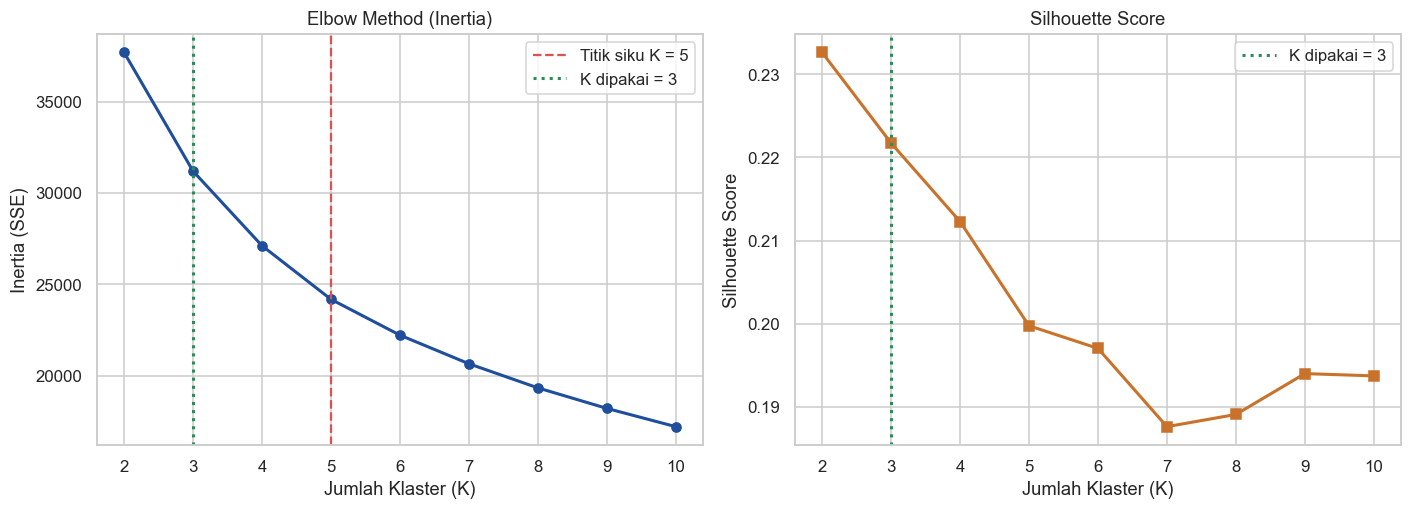

In [25]:
# 6.1 Grafik Elbow Method dan Silhouette Score
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
axes[0].plot(eval_df["K"], eval_df["inertia"], "o-", color="#1F4E9C", lw=2)
axes[0].axvline(K_ELBOW, color="#D9534F", ls="--", label=f"Titik siku K = {K_ELBOW}")
axes[0].axvline(K_FINAL, color="#2E8B57", ls=":", lw=2, label=f"K dipakai = {K_FINAL}")
axes[0].set(title="Elbow Method (Inertia)", xlabel="Jumlah Klaster (K)", ylabel="Inertia (SSE)"); axes[0].legend()

axes[1].plot(eval_df["K"], eval_df["silhouette"], "s-", color="#C9722B", lw=2)
axes[1].axvline(K_FINAL, color="#2E8B57", ls=":", lw=2, label=f"K dipakai = {K_FINAL}")
axes[1].set(title="Silhouette Score", xlabel="Jumlah Klaster (K)", ylabel="Silhouette Score"); axes[1].legend()
for ax in axes: ax.set_xticks(K_RANGE)
plt.tight_layout(); plt.show()

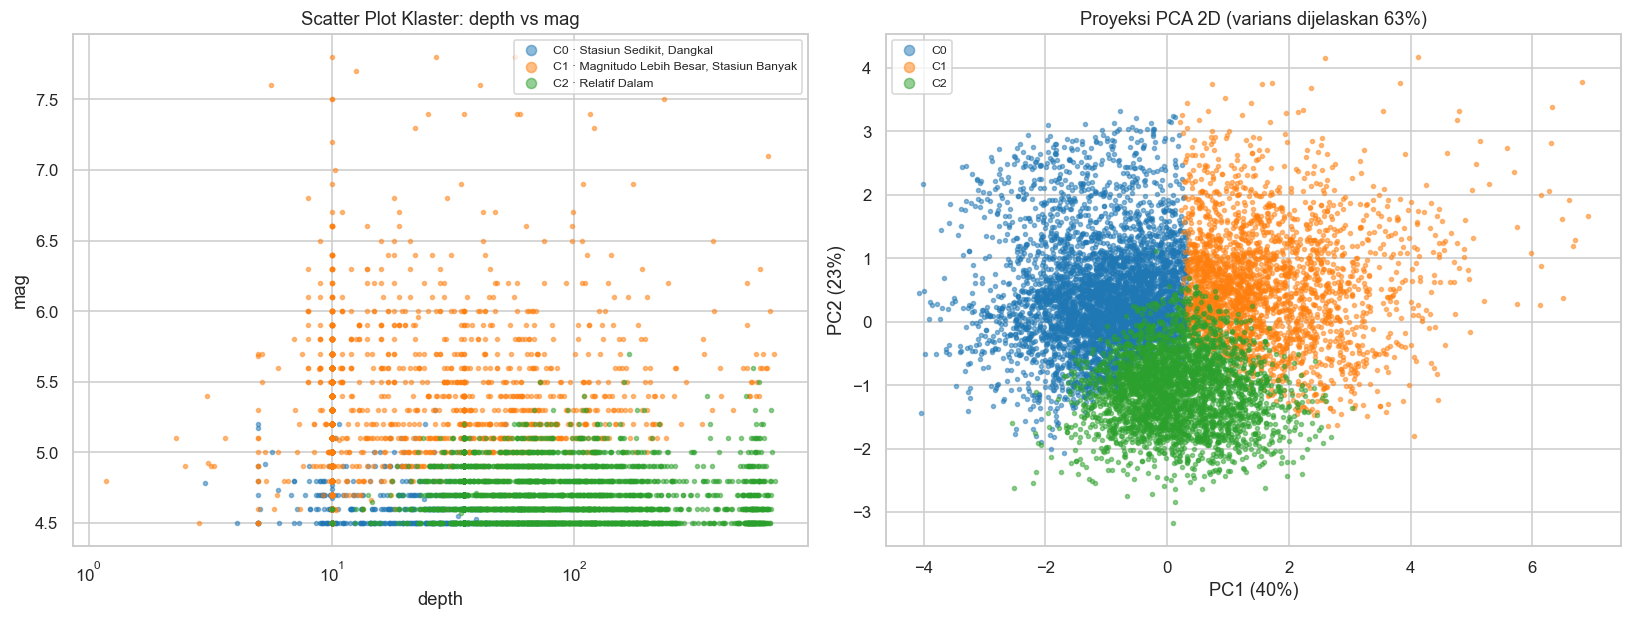

In [26]:
# 6.2 Scatter plot 2D berdasarkan dua fitur utama (hasil ANOVA) + proyeksi PCA
PALET = sns.color_palette("tab10", K_FINAL)
fx, fy = TOP_FEATURES[0], TOP_FEATURES[1]
pca = PCA(n_components=2, random_state=SEED).fit(X_scaled)
Xp = pca.transform(X_scaled)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.8))
for c in range(K_FINAL):
    m = labels == c
    axes[0].scatter(df.loc[m, fx], df.loc[m, fy], s=7, alpha=0.5, color=PALET[c], label=nama[c])
    axes[1].scatter(Xp[m, 0], Xp[m, 1], s=7, alpha=0.5, color=PALET[c], label=f"C{c}")
if fx in LOG_FEATURES: axes[0].set_xscale("log")
if fy in LOG_FEATURES: axes[0].set_yscale("log")
axes[0].set(title=f"Scatter Plot Klaster: {fx} vs {fy}", xlabel=fx, ylabel=fy); axes[0].legend(markerscale=2.5, fontsize=8)
axes[1].set(title=f"Proyeksi PCA 2D (varians dijelaskan {pca.explained_variance_ratio_.sum():.0%})",
            xlabel=f"PC1 ({pca.explained_variance_ratio_[0]:.0%})", ylabel=f"PC2 ({pca.explained_variance_ratio_[1]:.0%})")
axes[1].legend(markerscale=2.5, fontsize=8)
plt.tight_layout(); plt.show()

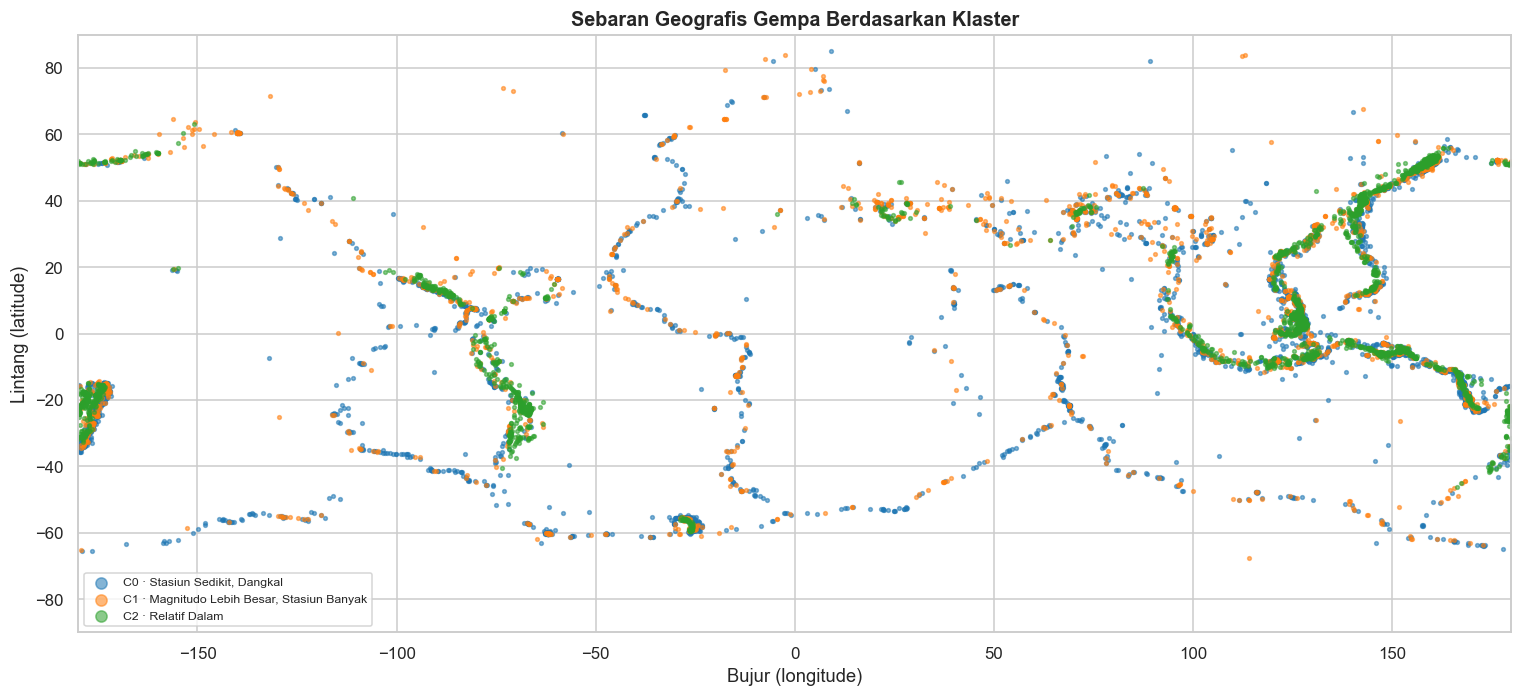

In [27]:
# 6.3 Peta sebaran gempa per klaster (longitude vs latitude)
plt.figure(figsize=(14, 6.5))
for c in range(K_FINAL):
    m = labels == c
    plt.scatter(df.loc[m, "longitude"], df.loc[m, "latitude"], s=6, alpha=0.55, color=PALET[c], label=nama[c])
plt.xlim(-180, 180); plt.ylim(-90, 90)
plt.title("Sebaran Geografis Gempa Berdasarkan Klaster", fontsize=13, fontweight="bold")
plt.xlabel("Bujur (longitude)"); plt.ylabel("Lintang (latitude)"); plt.legend(markerscale=3, fontsize=8, loc="lower left")
plt.tight_layout(); plt.show()

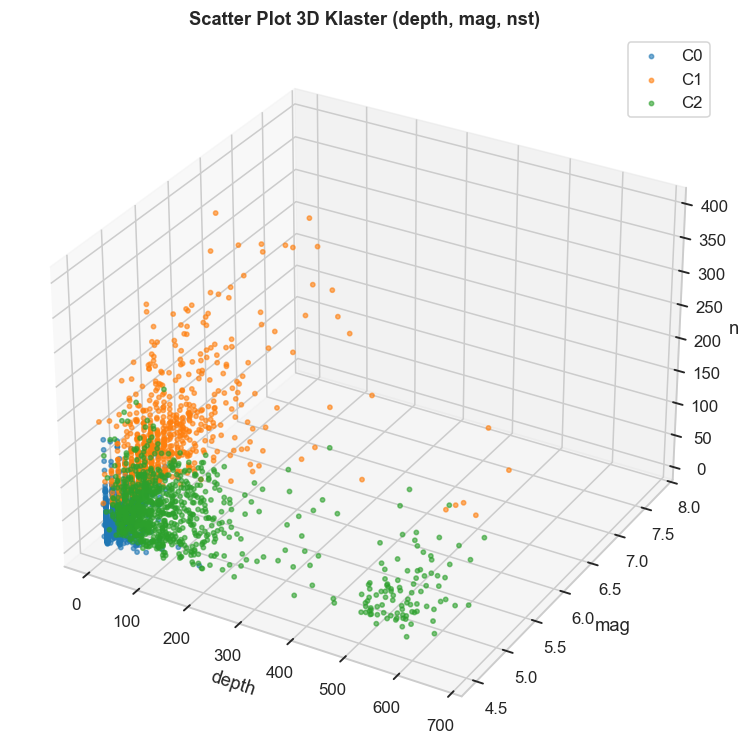

In [28]:
# 6.4 Scatter plot 3D (tiga fitur utama, sampel 3.000 titik)
f3 = TOP_FEATURES[:3]
samp = df.sample(3000, random_state=SEED)
fig = plt.figure(figsize=(9, 7)); ax = fig.add_subplot(111, projection="3d")
for c in range(K_FINAL):
    s = samp[samp["cluster"] == c]
    ax.scatter(s[f3[0]], s[f3[1]], s[f3[2]], s=8, alpha=0.6, color=PALET[c], label=f"C{c}")
ax.set_xlabel(f3[0]); ax.set_ylabel(f3[1]); ax.set_zlabel(f3[2])
ax.set_title(f"Scatter Plot 3D Klaster ({f3[0]}, {f3[1]}, {f3[2]})", fontweight="bold"); ax.legend()
plt.tight_layout(); plt.show()

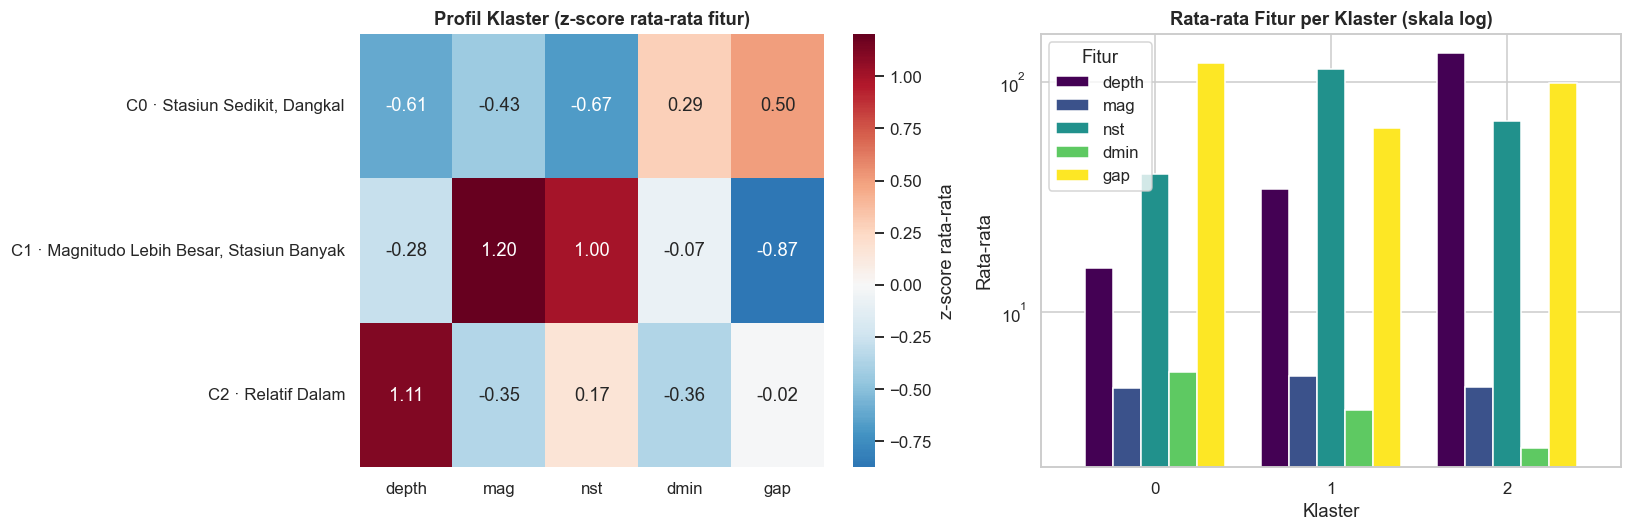

,jumlah,%,depth,mag,nst,dmin,gap,rms,sig,tsunami
cluster,,,,,,,,,,
0,4441,44.5,15.41,4.65,39.85,5.45,121.52,0.76,334.56,0.00
1,2478,24.8,34.11,5.25,114.29,3.73,62.89,0.76,441.28,0.03
2,3065,30.7,133.24,4.68,67.74,2.55,99.37,0.76,339.07,0.00


In [29]:
# 6.5 Mean/median tiap klaster: heatmap z-score + bar chart
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
zt = z_profil.copy(); zt.index = [nama[c] for c in zt.index]
sns.heatmap(zt, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=axes[0], cbar_kws={"label": "z-score rata-rata"})
axes[0].set_title("Profil Klaster (z-score rata-rata fitur)", fontweight="bold"); axes[0].tick_params(axis="y", rotation=0)

mean_tbl[FEATURES].plot(kind="bar", ax=axes[1], width=0.8, colormap="viridis")
axes[1].set_yscale("log"); axes[1].set_title("Rata-rata Fitur per Klaster (skala log)", fontweight="bold")
axes[1].set_xlabel("Klaster"); axes[1].set_ylabel("Rata-rata"); axes[1].tick_params(axis="x", rotation=0); axes[1].legend(title="Fitur")
plt.tight_layout(); plt.show()
display(mean_tbl.round(2))

---
## Langkah 7 — Simpan Hasil untuk Dashboard Streamlit
Dataset hasil clustering dan metadata disimpan ke `artifacts/`. Dashboard dijalankan dengan:
```bash
streamlit run app.py
```

In [30]:
# Simpan dataset hasil clustering (dengan kolom 'cluster') dan metadata untuk dashboard
df_hasil = df[KOLOM_SIMPAN + ["cluster", "cluster_name"]].copy()
df_hasil.to_csv(ARTIFACTS_DIR / "dataset_hasil_clustering.csv", index=False)

meta = {
    "features": FEATURES,
    "log_features": LOG_FEATURES,
    "k_final": int(K_FINAL),
    "k_elbow": int(K_ELBOW),
    "k_range": K_RANGE,
    "seed": SEED,
    "n_init": N_INIT,
    "eval": eval_df.round(6).to_dict(orient="records"),
    "raw_rows": int(len(df_raw)),
    "raw_cols": int(df_raw.shape[1] - 1),
    "clean_rows": int(len(df)),
    "cleaning_log": [[a, int(n)] for a, n in cleaning_log],
    "date_min": f"{df['waktu'].min():%Y-%m-%d}",
    "date_max": f"{df['waktu'].max():%Y-%m-%d}",
    "feature_roles": peran_fitur.values.tolist(),
    "top_features": TOP_FEATURES,
    "silhouette_final": sil_global,
    "inertia_final": inertia,
}
with open(ARTIFACTS_DIR / "clustering_meta.json", "w", encoding="utf-8") as f:
    json.dump(meta, f, ensure_ascii=False, indent=2)

print("[SUKSES] Artefak tersimpan di:", ARTIFACTS_DIR.resolve())
for p in sorted(ARTIFACTS_DIR.glob("*")):
    print(f"  - {p.name}  ({p.stat().st_size / 1024:,.0f} KB)")
print("\nJalankan dashboard:  streamlit run app.py")

[SUKSES] Artefak tersimpan di: C:\test3 Clustering K-Means\artifacts
  - clustering_meta.json  (3 KB)
  - dataset_hasil_clustering.csv  (3,472 KB)
  - dataset_siap_clustering.csv  (3,138 KB)

Jalankan dashboard:  streamlit run app.py
